# EN3330 Assignment 03: Lagrangian duality plots

Problem: $\min_x x^2$ subject to $x \ge 1$, i.e. $h(x)=1-x\le 0$.  
Lagrangian: $L(\mu,x)=x^2+\mu(1-x),\ \mu\ge 0$.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "lines.linewidth": 2, "axes.grid": True, "grid.alpha": 0.3,
})
COLORS = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]
SHADE = "0.9"          # feasible-region shading

def f(x):            return x**2
def h(x):            return 1 - x
def L(mu, x):        return f(x) + mu * h(x)
def x_of_mu(mu):     return mu / 2            # argmin_x L(mu, x)  (from dL/dx = 2x - mu = 0)
def d(mu):           return mu - mu**2 / 4    # dual function d(mu) = L(mu, mu/2)

def save(name):
    plt.savefig(f"figures/{name}.png")

## Q1(a): $L(\mu,x)$ for $\mu=0,1,2,3$

Setting $\partial L/\partial x = 2x-\mu = 0$ gives $x(\mu)=\mu/2$. The minimizer moves to the right as $\mu$ grows and enters the feasible region ($x\ge1$) at $\mu=2$.

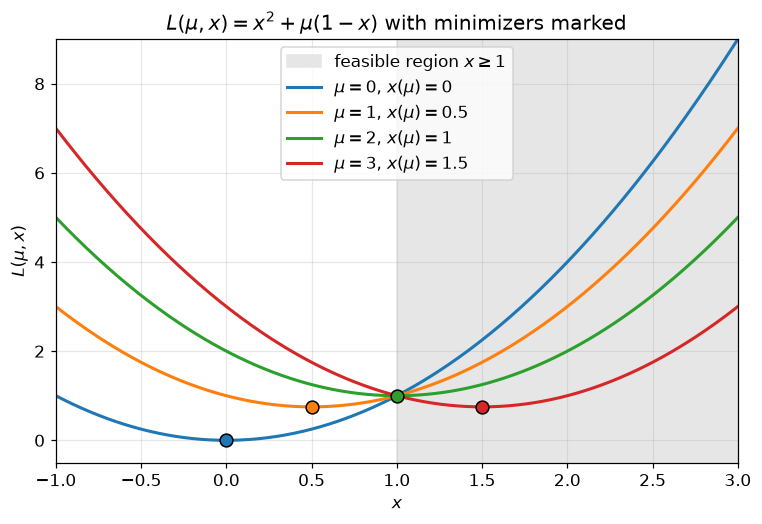

In [2]:
x = np.linspace(-1, 3, 400)
fig, ax = plt.subplots(figsize=(8, 5))
ax.axvspan(1, 3, color=SHADE, label="feasible region $x \\geq 1$")

for mu, c in zip([0, 1, 2, 3], COLORS):
    xm = x_of_mu(mu)
    ax.plot(x, L(mu, x), color=c, label=f"$\\mu={mu}$, $x(\\mu)={xm:g}$")
    ax.scatter(xm, L(mu, xm), color=c, s=70, edgecolor="k", zorder=5)

ax.set(xlim=(-1, 3), ylim=(-0.5, 9), xlabel="$x$", ylabel="$L(\\mu,x)$",
       title="$L(\\mu,x)=x^2+\\mu(1-x)$ with minimizers marked")
ax.legend(loc="upper center")
save("q1_a"); plt.show()

## Q1(b): Dual function

Substituting $x=\mu/2$: $d(\mu)=\mu^2/4+\mu-\mu^2/2=\mu-\mu^2/4$. Then $d'(\mu)=1-\mu/2=0\Rightarrow\mu^*=2$ and $d^*=d(2)=1$.

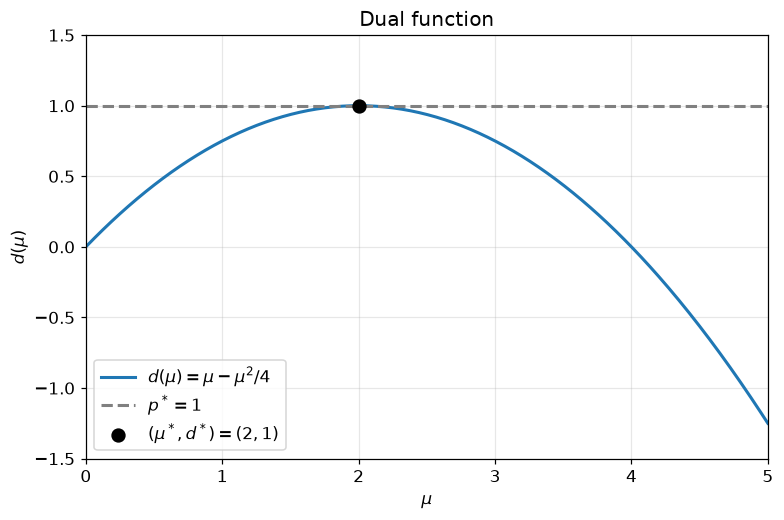

In [3]:
mu = np.linspace(0, 5, 400)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(mu, d(mu), color=COLORS[0], label=r"$d(\mu)=\mu-\mu^2/4$")
ax.axhline(1, color="gray", ls="--", label="$p^*=1$")
ax.scatter(2, d(2), color="k", s=70, zorder=5, label=r"$(\mu^*,d^*)=(2,1)$")
ax.set(xlim=(0, 5), ylim=(-1.5, 1.5), xlabel=r"$\mu$", ylabel=r"$d(\mu)$", title="Dual function")
ax.legend(loc="lower left")
save("q1_b"); plt.show()

## Q1(c): Primal function $g(x)=\max_{\mu\ge0}L(\mu,x)$

For $x\ge1$, $\mu(1-x)\le0$, so the maximum is at $\mu=0$ and $g(x)=x^2$. For $x<1$, $\mu(1-x)\to\infty$ as $\mu\to\infty$, so $g(x)=+\infty$. The right panel truncates $\mu\le M$ to show the blow-up numerically.

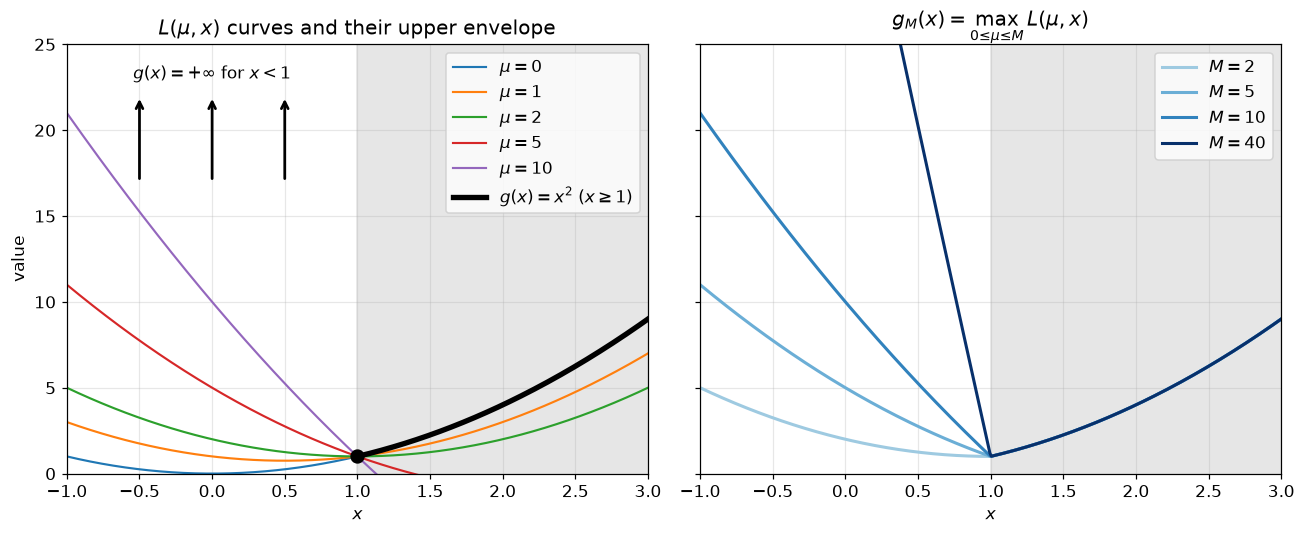

In [4]:
x = np.linspace(-1, 3, 400)
feasible = x >= 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax in (ax1, ax2):
    ax.axvspan(1, 3, color=SHADE)
    ax.set(xlim=(-1, 3), ylim=(0, 25), xlabel="$x$")

# left: L(mu,x) curves and g(x) on the feasible side
for mu, c in zip([0, 1, 2, 5, 10], COLORS):
    ax1.plot(x, L(mu, x), color=c, lw=1.4, label=fr"$\mu={mu}$")
ax1.plot(x[feasible], f(x[feasible]), "k", lw=3.5, label=r"$g(x)=x^2$ ($x\geq1$)")
ax1.scatter(1, 1, color="k", s=70, zorder=5)
for xa in (-0.5, 0, 0.5):
    ax1.annotate("", xy=(xa, 22), xytext=(xa, 17), arrowprops=dict(arrowstyle="->", lw=1.8))
ax1.text(0, 23, r"$g(x)=+\infty$ for $x<1$", ha="center")
ax1.set(ylabel="value", title=r"$L(\mu,x)$ curves and their upper envelope")
ax1.legend(loc="upper right")

# right: g_M(x) = max_{0<=mu<=M} L(mu,x) = x^2 + M*max(1-x,0)
for M, shade in zip([2, 5, 10, 40], ["#9ecae1", "#6baed6", "#3182bd", "#08306b"]):
    ax2.plot(x, f(x) + M * np.maximum(h(x), 0), color=shade, label=f"$M={M}$")
ax2.set(title=r"$g_M(x)=\max_{0\leq\mu\leq M}L(\mu,x)$")
ax2.legend(loc="upper right")

plt.tight_layout(); save("q1_c"); plt.show()

## Q2(a): Saddle point at $(x^*,\mu^*)=(1,2)$

(i) $L(2,1)=1+2\cdot0=1$.  (ii) $L(\mu,1)=1+\mu\cdot 0=1$ for every $\mu$, so $L(\mu,x^*)\le L(\mu^*,x^*)$ holds with equality.  (iii) $L(2,x)=x^2+2-2x=(x-1)^2+1\ge1$.

The code below checks both inequalities numerically on a grid, then plots them.

In [5]:
mu_g = np.linspace(0, 10, 2001)
x_g  = np.linspace(-5, 5, 2001)
Lstar = L(2, 1)
left_ok  = np.all(L(mu_g, 1) <= Lstar + 1e-12)
right_ok = np.all(Lstar <= L(2, x_g) + 1e-12)
print(f"L(mu*, x*) = {Lstar}")
print("Left inequality  L(mu,x*) <= L(mu*,x*) on grid:", left_ok)
print("Right inequality L(mu*,x*) <= L(mu*,x)  on grid:", right_ok)

L(mu*, x*) = 1
Left inequality  L(mu,x*) <= L(mu*,x*) on grid: True
Right inequality L(mu*,x*) <= L(mu*,x)  on grid: True


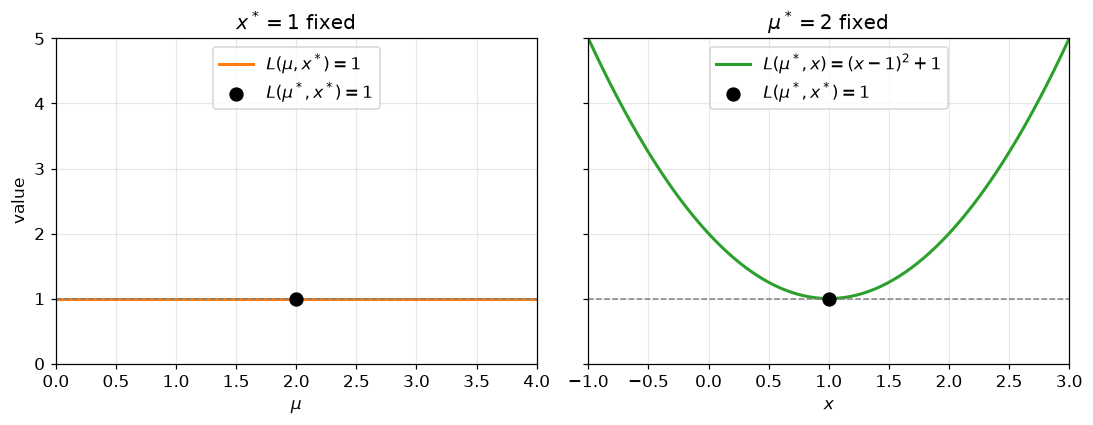

In [6]:
mu = np.linspace(0, 4, 400)
x  = np.linspace(-1, 3, 400)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ax1.plot(mu, L(mu, 1), color=COLORS[1], label=r"$L(\mu,x^*)=1$")
ax1.set(xlim=(0, 4), ylim=(0, 5), xlabel=r"$\mu$", ylabel="value", title=r"$x^*=1$ fixed")

ax2.plot(x, L(2, x), color=COLORS[2], label=r"$L(\mu^*,x)=(x-1)^2+1$")
ax2.set(xlim=(-1, 3), xlabel="$x$", title=r"$\mu^*=2$ fixed")

for ax, p in ((ax1, 2), (ax2, 1)):
    ax.axhline(1, color="gray", ls="--", lw=1)
    ax.scatter(p, 1, color="k", s=70, zorder=5, label=r"$L(\mu^*,x^*)=1$")
    ax.legend(loc="upper center")
plt.tight_layout(w_pad=2); save("q2_a"); plt.show()

## Q2(c): Active vs inactive constraint

Complementary slackness: $\mu^*h(x^*)=2\cdot0=0$. For $x\ge-1$ write $h(x)=-1-x\le0$. The unconstrained minimizer $x=0$ is feasible, and $h(0)=-1<0$, so the constraint is **inactive** there and we expect $\mu^*=0$ (complementary slackness).  
The dual becomes $d(\mu)=-\mu-\mu^2/4$, which is maximized at $\mu=0$ with $d^*=0=p^*$.

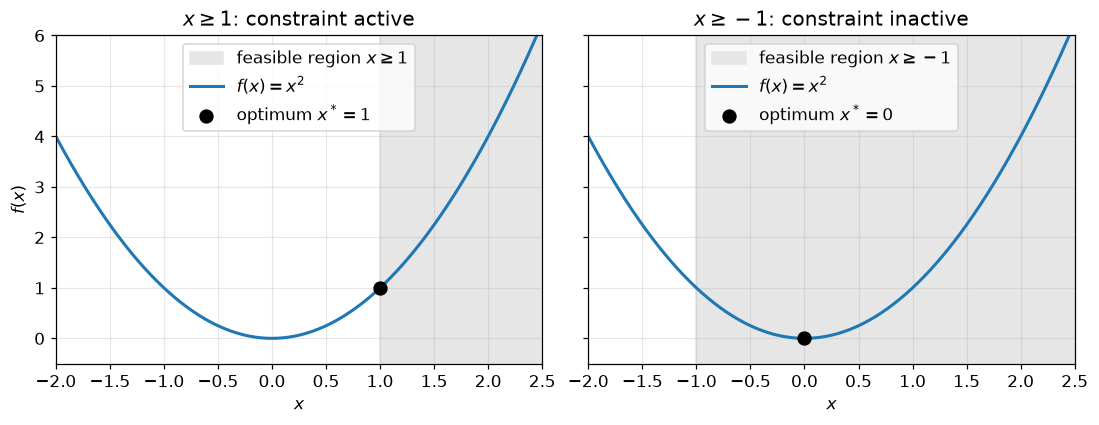

In [7]:
x = np.linspace(-2, 2.5, 400)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, b, xs, ttl in zip(axes, [1, -1], [1, 0],
                          ["$x\\geq1$: constraint active", "$x\\geq-1$: constraint inactive"]):
    ax.axvspan(b, 2.5, color=SHADE, label=f"feasible region $x\\geq{b}$")
    ax.plot(x, f(x), color=COLORS[0], label="$f(x)=x^2$")
    ax.scatter(xs, f(xs), color="k", s=70, zorder=5, label=f"optimum $x^*={xs}$")
    ax.set(xlim=(-2, 2.5), ylim=(-0.5, 6), xlabel="$x$", title=ttl)
    ax.legend(loc="upper center")
axes[0].set_ylabel("$f(x)$")
plt.tight_layout(w_pad=2); save("q2_c_compare"); plt.show()

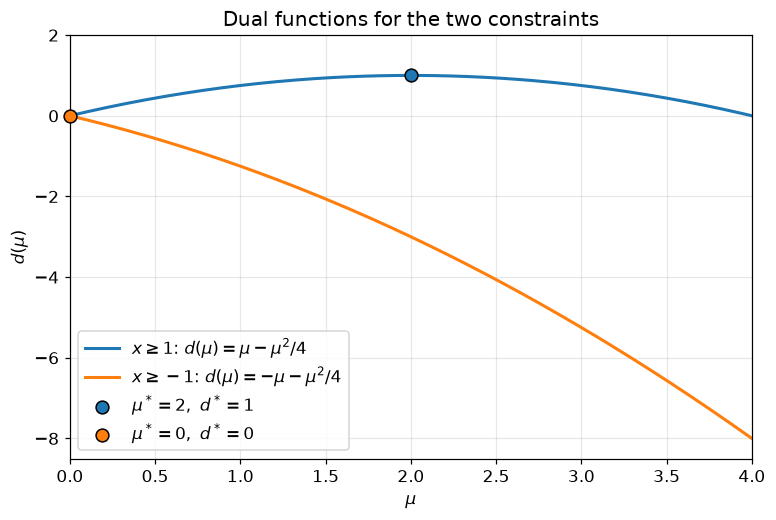

In [8]:
mu = np.linspace(0, 4, 400)
d_a = mu - mu**2 / 4          # constraint x >= 1
d_b = -mu - mu**2 / 4         # constraint x >= -1

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(mu, d_a, color=COLORS[0], label=r"$x\geq1$: $d(\mu)=\mu-\mu^2/4$")
ax.plot(mu, d_b, color=COLORS[1], label=r"$x\geq-1$: $d(\mu)=-\mu-\mu^2/4$")
ax.scatter(2, 1, color=COLORS[0], s=70, edgecolor="k", zorder=5, label=r"$\mu^*=2,\ d^*=1$")
ax.scatter(0, 0, color=COLORS[1], s=70, edgecolor="k", zorder=5, clip_on=False, label=r"$\mu^*=0,\ d^*=0$")
ax.set(xlim=(0, 4), ylim=(-8.5, 2), xlabel=r"$\mu$", ylabel=r"$d(\mu)$", title="Dual functions for the two constraints")
ax.legend(loc="lower left")
save("q2_c_dual"); plt.show()

## Q3(a): Numerical check of weak duality, $d(\mu)\le p^*=1$

In [13]:
p_star = 1
print(f"{'mu':>3} | {'d(mu)':>7} | d(mu) <= p* ?")
print("-" * 30)
for m in [0, 1, 2, 3]:
    print(f"{m:>3} | {d(m):>7.3f} | {d(m) <= p_star}")

# also check against L(mu, x) for feasible x (the intermediate inequality in the proof)
xf = np.linspace(1, 5, 200)
print("\nd(mu) <= L(mu,x) <= f(x) for all feasible x, mu in {0,1,2,3}:",
      all(np.all(d(m) <= L(m, xf) + 1e-12) and np.all(L(m, xf) <= f(xf) + 1e-12) for m in [0, 1, 2, 3]))

 mu |   d(mu) | d(mu) <= p* ?
------------------------------
  0 |   0.000 | True
  1 |   0.750 | True
  2 |   1.000 | True
  3 |   0.750 | True

d(mu) <= L(mu,x) <= f(x) for all feasible x, mu in {0,1,2,3}: True


## Q3(b): Lines $L(\mu,x)$ in $\mu$ and their lower envelope

For fixed $x$, $L(\mu,x)=f(x)+\mu h(x)$ is a straight line in $\mu$. $d(\mu)$ is the pointwise minimum over $x$ of these lines. A pointwise minimum of linear (hence concave) functions is concave, whatever $f$ is.

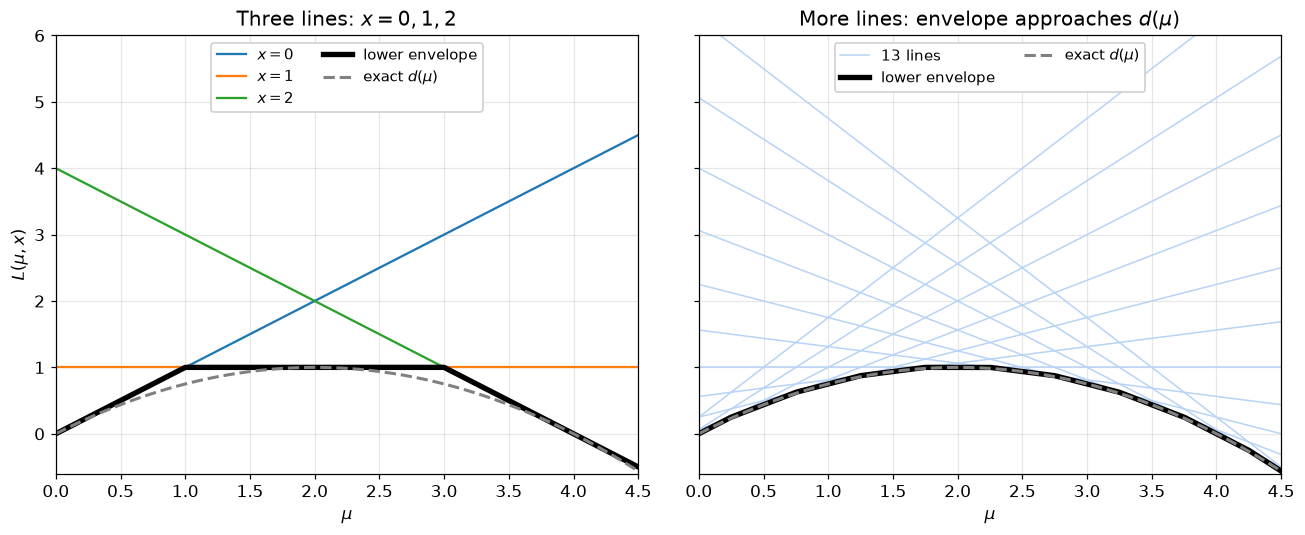

In [14]:
mu = np.linspace(0, 4.5, 400)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# left: x = 0, 1, 2
xs = [0, 1, 2]
lines = np.array([L(mu, xv) for xv in xs])
for xv, ln, c in zip(xs, lines, COLORS):
    ax1.plot(mu, ln, color=c, lw=1.5, label=f"$x={xv}$")
ax1.plot(mu, lines.min(axis=0), "k", lw=3.5, label="lower envelope")
ax1.set(ylabel=r"$L(\mu,x)$", title="Three lines: $x=0,1,2$")

# right: many x
xs_many = np.arange(-0.5, 2.51, 0.25)
many = np.array([L(mu, xv) for xv in xs_many])
for k, ln in enumerate(many):
    ax2.plot(mu, ln, color="#b7d3f6", lw=1, label="13 lines" if k == 0 else None)
ax2.plot(mu, many.min(axis=0), "k", lw=3.5, label="lower envelope")
ax2.set(title="More lines: envelope approaches $d(\\mu)$")

for ax in (ax1, ax2):
    ax.plot(mu, d(mu), color="gray", ls="--", label=r"exact $d(\mu)$")
    ax.set(xlim=(0, 4.5), ylim=(-0.6, 6), xlabel=r"$\mu$")
    ax.legend(loc="upper center", ncol=2, fontsize=9.5, framealpha=1)
plt.tight_layout(w_pad=2); save("q3_b"); plt.show()